# CloudGuard-Water: Phase 1 — Dataset Inspection & Verification

**Course**: Machine Learning for Cloud Services  
**Project**: CloudGuard-Water: Intelligent and Explainable Water Quality Classification  
**Dataset**: `data/water_quality_dataset1.csv`  

---

### Objectives:
1. Verify file size, row/column counts, and storage format.
2. Inspect schema and exact data types.
3. Validate data quality (missing values, exact duplicates, physical range validity).
4. Analyze target variable distribution (`Safe` vs. `Unsafe`) and calculate the class imbalance ratio.
5. Generate descriptive statistics (mean, median, std, min, max, IQR) for all 4 physical features.
6. Compute the numerical correlation matrix.
7. Conduct statistical outlier detection using Tukey's $1.5 \times \text{IQR}$ rule without removing valid observations.
8. Assess dataset suitability for machine-learning classification.


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid", palette="muted")


## 1. File Metadata & Dataset Loading
We locate the authoritative dataset using a multi-environment locator that works across local IDEs, terminal runs, and remote environments.


In [2]:
def find_dataset():
    candidates = [
        Path("data/water_quality_dataset1.csv"),
        Path("../data/water_quality_dataset1.csv"),
        Path("../../data/water_quality_dataset1.csv"),
        Path("data/water_quality_dataset1_original.csv"),
        Path("../data/water_quality_dataset1_original.csv"),
        Path("Cloudguard/data/water_quality_dataset1.csv"),
        Path("/content/Cloudguard/data/water_quality_dataset1.csv"),
        Path("/content/data/water_quality_dataset1.csv"),
    ]
    for p in candidates:
        if p.exists():
            return p
    curr = Path.cwd().resolve()
    for parent in [curr] + list(curr.parents):
        for name in ["water_quality_dataset1.csv", "water_quality_dataset1_original.csv"]:
            target = parent / "data" / name
            if target.exists():
                return target
    raise FileNotFoundError("Could not find dataset in standard locations.")

data_file = find_dataset()
file_size = data_file.stat().st_size

print(f"File Path    : {data_file.resolve()}")
print(f"File Size    : {file_size:,} bytes ({file_size / (1024*1024):.2f} MB)")
print(f"File Format  : CSV")

df = pd.read_csv(data_file)
print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head(10)


File Path    : D:\E0224033\ML_for_Cl_Ser\CL\LB_Proj\data\water_quality_dataset1.csv
File Size    : 2,964,409 bytes (2.83 MB)
File Format  : CSV
Dataset Shape: 100,800 rows × 5 columns


,pH,TDS_ppm,Turbidity_NTU,Temperature_C,Label
0,7.38,138.7,0.25,20.25,Safe
1,7.42,79.2,0.45,20.14,Safe
2,7.05,104.1,1.18,20.12,Safe
3,7.32,112.8,0.53,19.65,Safe
4,6.87,171.9,1.97,19.42,Safe
5,7.19,82.3,2.25,19.49,Safe
6,7.14,102.2,0.53,20.10,Safe
7,6.94,156.1,1.28,19.50,Safe
8,6.84,175.3,0.52,20.16,Safe
9,7.43,156.1,0.21,20.29,Safe


## 2. Schema & Exact Column Data Types
Checking exact column names, pandas dtypes, and memory usage.


In [3]:
schema_info = []
for col in df.columns:
    schema_info.append({
        'Column Name': col,
        'Pandas dtype': str(df[col].dtype),
        'Non-Null Count': df[col].notnull().sum(),
        'Sample Value': df[col].iloc[0]
    })

schema_df = pd.DataFrame(schema_info)
print(f"In-Memory Usage: {df.memory_usage(deep=True).sum() / (1024*1024):.2f} MB")
schema_df


In-Memory Usage: 9.07 MB


,Column Name,Pandas dtype,Non-Null Count,Sample Value
0,pH,float64,100800,7.38
1,TDS_ppm,float64,100800,138.7
2,Turbidity_NTU,float64,100800,0.25
3,Temperature_C,float64,100800,20.25
4,Label,object,100800,Safe


## 3. Data Quality & Physical Validity Checks
Verifying missing values, duplicate rows, and whether all values adhere to known physical boundaries:
- **pH**: Must be within $[0, 14]$
- **TDS_ppm**: Must be $\ge 0$
- **Turbidity_NTU**: Must be $\ge 0$
- **Temperature_C**: Plausible range $[-10, 100\,^\circ\text{C}]$


In [4]:
print("Missing Values per Column:")
print(df.isnull().sum())
print(f"\nTotal Missing Values : {df.isnull().sum().sum()}")
print(f"Exact Duplicate Rows : {df.duplicated().sum()}")

# Physical boundary checks
range_checks = {
    'pH': (0, 14),
    'TDS_ppm': (0, 50000),
    'Turbidity_NTU': (0, 10000),
    'Temperature_C': (-10, 100)
}

print("\nPhysical Plausibility Checks:")
for col, (lo, hi) in range_checks.items():
    viol = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"  {col:<18}: {viol} values outside [{lo}, {hi}]")


Missing Values per Column:
pH               0
TDS_ppm          0
Turbidity_NTU    0
Temperature_C    0
Label            0
dtype: int64

Total Missing Values : 0
Exact Duplicate Rows : 0

Physical Plausibility Checks:
  pH                : 0 values outside [0, 14]
  TDS_ppm           : 0 values outside [0, 50000]
  Turbidity_NTU     : 0 values outside [0, 10000]
  Temperature_C     : 0 values outside [-10, 100]


## 4. Target Variable Analysis (`Label`)
Analyzing class distribution, frequencies, and the imbalance ratio between `Safe` and `Unsafe`.


  Unsafe  :  70,560 samples (70.00%)


  Safe    :  30,240 samples (30.00%)

Imbalance Ratio (Unsafe : Safe): 2.33 : 1


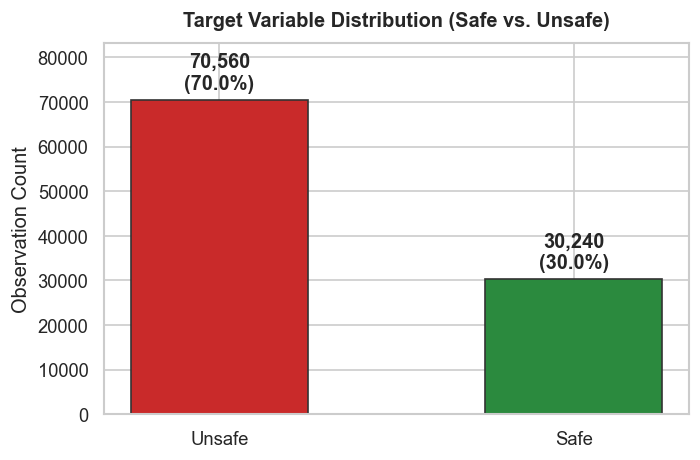

In [5]:
counts = df['Label'].value_counts()
percs = df['Label'].value_counts(normalize=True) * 100

for lbl in counts.index:
    print(f"  {lbl:<8}: {counts[lbl]:>7,} samples ({percs[lbl]:>5.2f}%)")

imbalance_ratio = counts['Unsafe'] / counts['Safe']
print(f"\nImbalance Ratio (Unsafe : Safe): {imbalance_ratio:.2f} : 1")

fig, ax = plt.subplots(figsize=(6, 4))
palette = {"Safe": "#2b8a3e", "Unsafe": "#c92a2a"}
bars = ax.bar(counts.index, counts.values, color=[palette[c] for c in counts.index], edgecolor="#333", width=0.5)

for bar in bars:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    ax.text(bar.get_x() + bar.get_width()/2., h + 1500, f"{h:,}\n({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

ax.set_title("Target Variable Distribution (Safe vs. Unsafe)", fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel("Observation Count")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()


## 5. Numerical Feature Statistics & Per-Class Breakdown
Calculating descriptive statistics (mean, std, min, 25%, median, 75%, max) for each physical feature across the full dataset and grouped by class.


In [6]:
features = ['pH', 'TDS_ppm', 'Turbidity_NTU', 'Temperature_C']
desc = df[features].describe(percentiles=[0.25, 0.50, 0.75]).T
desc['median'] = df[features].median()

print("Overall Feature Statistics:")
print(desc[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max']].round(2))

print("\nPer-Class Means:")
class_means = df.groupby('Label')[features].mean().round(2)
class_means


Overall Feature Statistics:
                  count    mean     std    min     25%  median      75%  \
pH             100800.0    7.59    0.80   6.09    7.01    7.38     8.10   
TDS_ppm        100800.0  692.65  647.33  28.60  163.00  472.85  1023.32   
Turbidity_NTU  100800.0   11.31    9.87   0.00    1.92    9.97    18.54   
Temperature_C  100800.0   24.88    2.69  16.56   23.09   25.04    26.93   

                   max  
pH                9.96  
TDS_ppm        2806.10  
Turbidity_NTU    72.75  
Temperature_C    31.51  

Per-Class Means:


,pH,TDS_ppm,Turbidity_NTU,Temperature_C
Label,,,,
Safe,7.17,118.34,1.28,22.21
Unsafe,7.78,938.78,15.60,26.03


## 6. Feature Correlation Matrix
Evaluating pairwise linear correlations among input features and with the target.


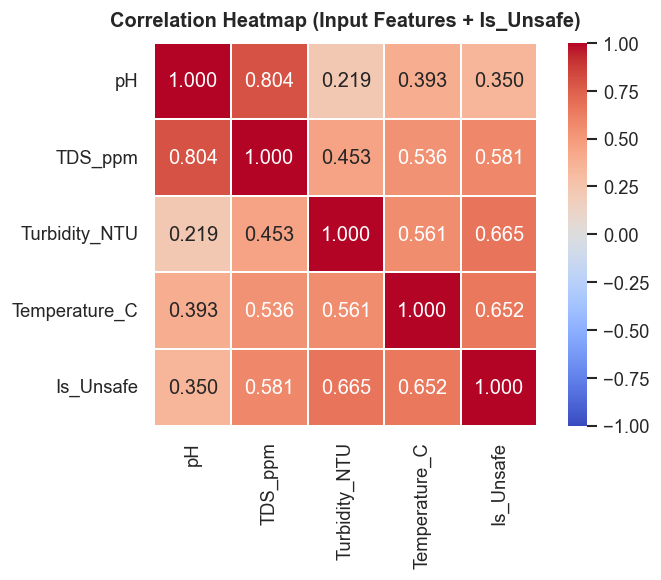

In [7]:
corr_df = df[features].copy()
corr_df['Is_Unsafe'] = (df['Label'] == 'Unsafe').astype(int)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1.0, vmax=1.0, center=0.0, square=True, linewidths=1.2, ax=ax)
ax.set_title("Correlation Heatmap (Input Features + Is_Unsafe)", fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


## 7. Statistical Outlier Detection (Tukey's 1.5 × IQR Rule)
Calculating upper and lower fences.
**Critical Decision**: We report these outliers but **do not remove them**, because high TDS (>2,300 ppm) and high turbidity (>43 NTU) represent real coastal saline and runoff conditions that the model must recognize.


In [8]:
outlier_summary = []
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower_fence) | (df[col] > upper_fence)).sum()
    outlier_summary.append({
        'Feature': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Lower Fence': round(lower_fence, 2),
        'Upper Fence': round(upper_fence, 2),
        'Outliers Count': n_outliers,
        '% Outliers': round(n_outliers / len(df) * 100, 2)
    })

pd.DataFrame(outlier_summary)


,Feature,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers Count,% Outliers
0,pH,7.01,8.10,1.09,5.38,9.74,423,0.42
1,TDS_ppm,163.00,1023.32,860.32,-1127.49,2313.81,3096,3.07
2,Turbidity_NTU,1.92,18.54,16.62,-23.01,43.47,118,0.12
3,Temperature_C,23.09,26.93,3.84,17.33,32.69,72,0.07


## 8. Phase 1 Assessment & Findings Summary

1. **Dataset Integrity**: 100,800 rows, 5 columns, 0 missing, 0 duplicates, 0 physically invalid readings.
2. **Target Balance**: 70.0% Unsafe, 30.0% Safe (2.33:1 imbalance ratio).
3. **Key Predictors**: TDS and Turbidity show significant mean separation between Safe and Unsafe classes.
4. **Temporal Note**: No timestamp exists in this dataset; therefore, this is a **cross-sectional classification task**, not time-series forecasting.
5. **Conclusion**: The dataset is completely clean and fully suitable for machine-learning classification.
